In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../../data/car_fuel_efficiency_2026.csv")

In [2]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [3]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [4]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [5]:
df = df[["engine_displacement", "horsepower", "vehicle_weight", "model_year", "fuel_efficiency_mpg"]]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


In [6]:
for col in df.columns:
    print(f"{col}:")
    # first 5
    print(f"Unique examples: {df[col].unique()[:5]}")
    print(f"Number of unique values: {df[col].nunique()}")
    print()

engine_displacement:
Unique examples: [2180 2390 2320 2130 2580]
Number of unique values: 127

horsepower:
Unique examples: [243. 272. 267. 258. 304.]
Number of unique values: 153

vehicle_weight:
Unique examples: [3870 4210 4240 4490 4510]
Number of unique values: 176

model_year:
Unique examples: [2006 2008 1996 1989 1994]
Number of unique values: 50

fuel_efficiency_mpg:
Unique examples: [31.9 31.3 27.5 28.5 31. ]
Number of unique values: 188



In [7]:
# Question 1
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [8]:
# Question 2
df['horsepower'].median()

np.float64(254.0)

In [9]:
# EDA
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

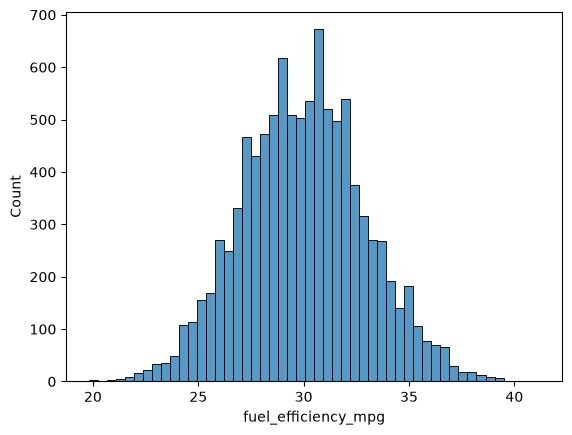

In [10]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)
# Does not have a long tail, has bell curve 

In [11]:
# Prepare and split the dataset
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [12]:
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

In [13]:
df_train = df_train.reset_index(drop = True)
df_val = df_val.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)

In [14]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

In [15]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [16]:
x_train = df_train.fillna(0).values
x_val = df_val.fillna(0).values

mean = df_train.horsepower.mean()

z_train = df_train.fillna(mean).values
z_val = df_val.fillna(mean).values

In [17]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [18]:
w0, w = train_linear_regression(x_train, y_train)
w0_mean, w_mean = train_linear_regression(z_train, y_train)

In [19]:
w0, w

(np.float64(-153.8849618823488),
 array([-1.51505520e-03, -4.74024795e-06, -3.95418397e-03,  1.02146785e-01]))

In [20]:
w0_mean, w_mean

(np.float64(-153.29645639137814),
 array([-0.00102386, -0.00648622, -0.00388828,  0.10197897]))

In [21]:
y_pred = w0 + x_val.dot(w)
y_pred_mean = w0_mean + z_val.dot(w_mean)

<Axes: ylabel='Count'>

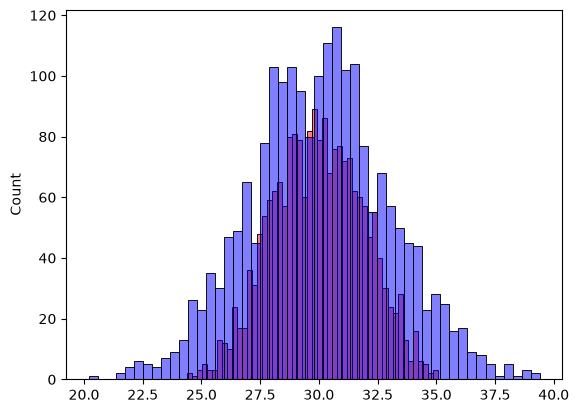

In [22]:
sns.histplot(y_pred, color='red', bins=50, alpha=0.5)
sns.histplot(y_test, color='blue', bins=50, alpha=0.5)

<Axes: ylabel='Count'>

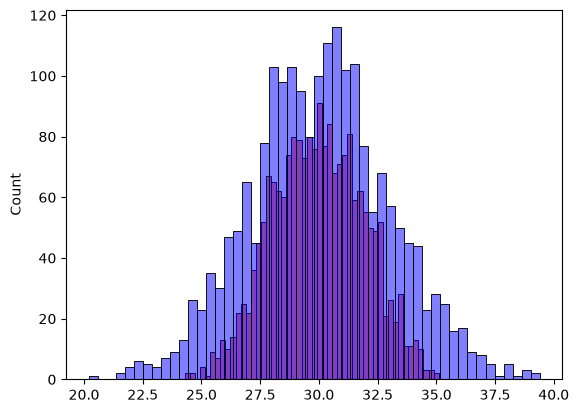

In [23]:
sns.histplot(y_pred_mean, color='red', bins=50, alpha=0.5)
sns.histplot(y_test, color='blue', bins=50, alpha=0.5)

In [24]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [25]:
print(round(rmse(y_val, y_pred), 3))

2.205


In [26]:
# Q3 lower is better so this is the better option 
print(round(rmse(y_val, y_pred_mean), 3))

2.202


In [42]:
def train_linear_regression_reg(X, y, r=0.01):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [28]:
x_train = df_train.fillna(0).values
x_val = df_val.fillna(0).values

In [29]:
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

In [30]:
for r in r_values:
    w0, w = train_linear_regression_reg(x_train, y_train, r)

    y_prediction = w0 + x_val.dot(w)

    score = rmse(y_val, y_prediction)

    print(r, round(score, 4))

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


In [34]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

scores = []

for seed in seeds:
    # Split sizes
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    # Shuffle using current seed
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    # Create splits
    df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
    df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
    df_test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)

    # Create target arrays for THIS split
    y_train = df_train['fuel_efficiency_mpg'].values
    y_val = df_val['fuel_efficiency_mpg'].values

    # Remove target from features
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    # Fill missing values with 0
    x_train = df_train.fillna(0).values
    x_val = df_val.fillna(0).values

    # Train model without regularization
    w0, w = train_linear_regression(x_train, y_train)

    # Predict on validation set
    y_pred = w0 + x_val.dot(w)

    # Calculate RMSE
    score = rmse(y_val, y_pred)

    scores.append(score)
    print(f"seed: {seed}, rmse: {round(score, 3)}")

std = np.std(scores)

print("std:", round(std, 3))

seed: 0, rmse: 2.239
seed: 1, rmse: 2.202
seed: 2, rmse: 2.163
seed: 3, rmse: 2.204
seed: 4, rmse: 2.202
seed: 5, rmse: 2.246
seed: 6, rmse: 2.27
seed: 7, rmse: 2.191
seed: 8, rmse: 2.217
seed: 9, rmse: 2.207
std: 0.029


In [43]:
# Split sizes
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

# Shuffle with seed 9
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

# Create splits
df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
df_test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)

# Create target arrays
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

# Remove target from features
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

# Combine train + validation features
df_train_full = pd.concat([df_train, df_val]).reset_index(drop=True)

# Combine train + validation targets
y_train_full = np.concatenate([y_train, y_val])

# Fill missing values with 0
x_train_full = df_train_full.fillna(0).values
x_test = df_test.fillna(0).values

# Train regularized model
w0, w = train_linear_regression_reg(
    x_train_full,
    y_train_full,
    r=0.001
)

# Predict on test set
y_pred = w0 + x_test.dot(w)

# Calculate test RMSE
score = rmse(y_test, y_pred)

print(round(score, 3))

2.236
